In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

score = pd.read_csv("admission_predict.csv")
score

/usr/lib/python3/dist-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.17.3 and <1.25.0 is required for this version of SciPy (detected version 1.26.0
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,1,337,118,4,4.5,4.5,9.65,1.0,0.92
1,2,324,107,4,4.0,4.5,8.87,1.0,0.76
2,3,316,104,3,3.0,3.5,8.00,1.0,0.72
3,4,322,110,3,3.5,2.5,8.67,1.0,0.80
4,5,314,103,2,2.0,3.0,8.21,0.0,0.65
...,...,...,...,...,...,...,...,...,...
395,396,324,110,3,3.5,3.5,9.04,1.0,0.82
396,397,325,107,3,3.0,3.5,9.11,1.0,0.84
397,398,330,116,4,5.0,4.5,9.45,1.0,0.91
398,399,312,103,3,3.5,4.0,8.78,0.0,0.67


In [3]:
score["selected"] = (score["Chance of Admit"]>0.87).astype(int)
score

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit,selected
0,1,337,118,4,4.5,4.5,9.65,1.0,0.92,1
1,2,324,107,4,4.0,4.5,8.87,1.0,0.76,0
2,3,316,104,3,3.0,3.5,8.00,1.0,0.72,0
3,4,322,110,3,3.5,2.5,8.67,1.0,0.80,0
4,5,314,103,2,2.0,3.0,8.21,0.0,0.65,0
...,...,...,...,...,...,...,...,...,...,...
395,396,324,110,3,3.5,3.5,9.04,1.0,0.82,0
396,397,325,107,3,3.0,3.5,9.11,1.0,0.84,0
397,398,330,116,4,5.0,4.5,9.45,1.0,0.91,1
398,399,312,103,3,3.5,4.0,8.78,0.0,0.67,0


In [4]:
score = score.drop(["Chance of Admit", "Serial No."], axis=1)
score

,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,selected
0,337,118,4,4.5,4.5,9.65,1.0,1
1,324,107,4,4.0,4.5,8.87,1.0,0
2,316,104,3,3.0,3.5,8.00,1.0,0
3,322,110,3,3.5,2.5,8.67,1.0,0
4,314,103,2,2.0,3.0,8.21,0.0,0
...,...,...,...,...,...,...,...,...
395,324,110,3,3.5,3.5,9.04,1.0,0
396,325,107,3,3.0,3.5,9.11,1.0,0
397,330,116,4,5.0,4.5,9.45,1.0,1
398,312,103,3,3.5,4.0,8.78,0.0,0


In [5]:
score.isnull().sum()

GRE Score            0
TOEFL Score          0
University Rating    0
SOP                  0
LOR                  0
CGPA                 0
Research             3
selected             0
dtype: int64

In [6]:
score.Research.median()

1.0

In [7]:
score["Research"] = score["Research"].fillna(score.Research.median())

In [8]:
score.isnull().sum()

GRE Score            0
TOEFL Score          0
University Rating    0
SOP                  0
LOR                  0
CGPA                 0
Research             0
selected             0
dtype: int64

In [9]:
x = score.drop("selected", axis=1)
y = score["selected"]

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [10]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.metrics import precision_score, recall_score, f1_score

model = DecisionTreeClassifier(criterion="entropy",random_state=42)
tree1 = model.fit(x_train, y_train)

In [11]:
predicted1 = tree1.predict(x_test)

In [13]:
print(f"Confusion Matrix:\n {confusion_matrix(y_test,predicted1)}")

Confusion Matrix:
 [[58  4]
 [ 1 17]]


In [15]:
print(f"Accuracy: {accuracy_score(y_test,predicted1)}")
print(f"Precision: {precision_score(y_test,predicted1)}")
print(f"Recall Score: {recall_score(y_test,predicted1)}")


Accuracy: 0.9375
Precision: 0.8095238095238095
Recall Score: 0.9444444444444444


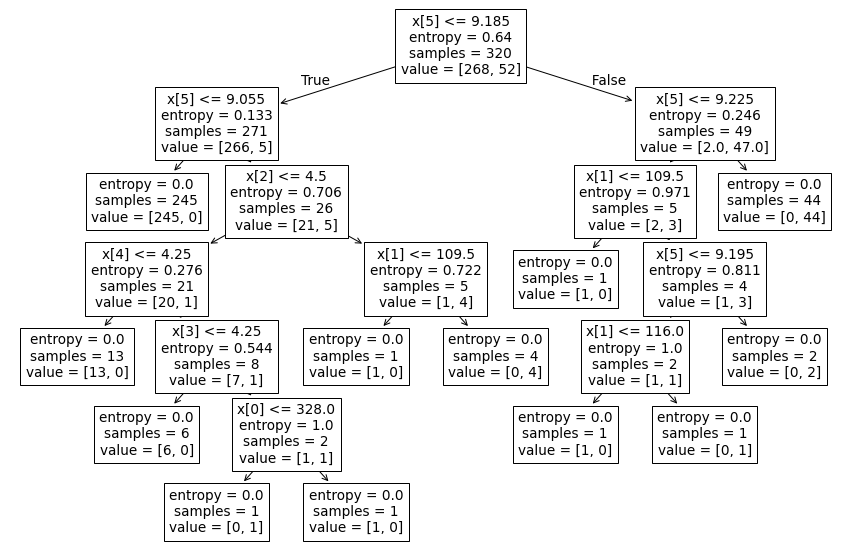

In [16]:
from sklearn.tree import plot_tree

plt.figure(figsize=(15,10))
plot_tree(tree1)
plt.show()

In [17]:
tree2 = DecisionTreeClassifier(criterion="gini",random_state=42)
tree2 = tree2.fit(x_train, y_train)

In [18]:
predicted2 = model.predict(x_test)

In [20]:
print(f"Confusion Matrix:\n {confusion_matrix(y_test,predicted2)}")

Confusion Matrix:
 [[58  4]
 [ 1 17]]


In [21]:
print(f"Accuracy: {accuracy_score(y_test,predicted2)}")
print(f"Precision: {precision_score(y_test,predicted2)}")
print(f"Recall Score: {recall_score(y_test,predicted2)}")

Accuracy: 0.9375
Precision: 0.8095238095238095
Recall Score: 0.9444444444444444


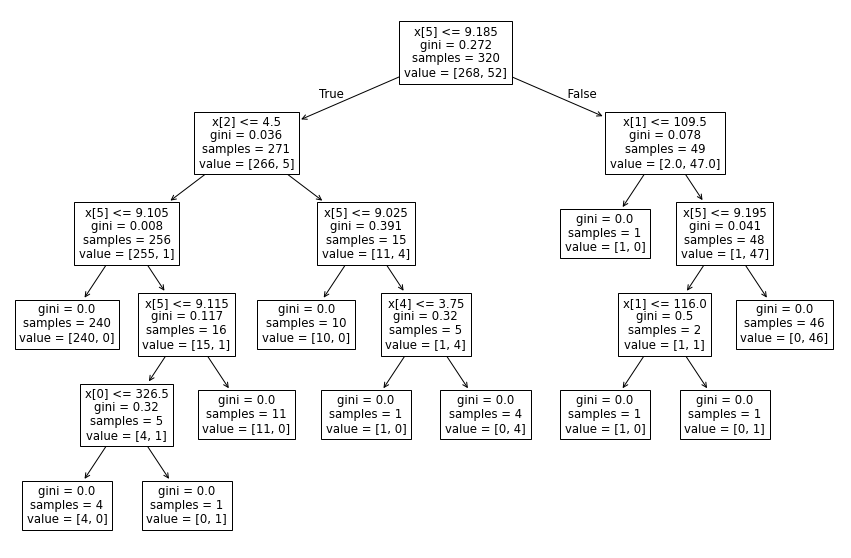

In [22]:
plt.figure(figsize=(15,10))
plot_tree(tree2)
plt.show()

In [23]:
from sklearn.naive_bayes import GaussianNB

naive = GaussianNB()
naive.fit(x_train, y_train)

predicted3 = naive.predict(x_test)

In [24]:
print(f"Confusion Matrix:\n {confusion_matrix(y_test, predicted3)}")

Confusion Matrix:
 [[57  5]
 [ 1 17]]


In [25]:
print("Accuracy:", accuracy_score(y_test, predicted3))
print("Precision:", precision_score(y_test, predicted3, zero_division=0))
print("Recall:", recall_score(y_test, predicted3, zero_division=0))
print("F1-Score:", f1_score(y_test, predicted3, zero_division=0))

Accuracy: 0.925
Precision: 0.7727272727272727
Recall: 0.9444444444444444
F1-Score: 0.85


In [26]:
score.columns

Index(['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA',
       'Research', 'selected'],
      dtype='object')

<AxesSubplot:>

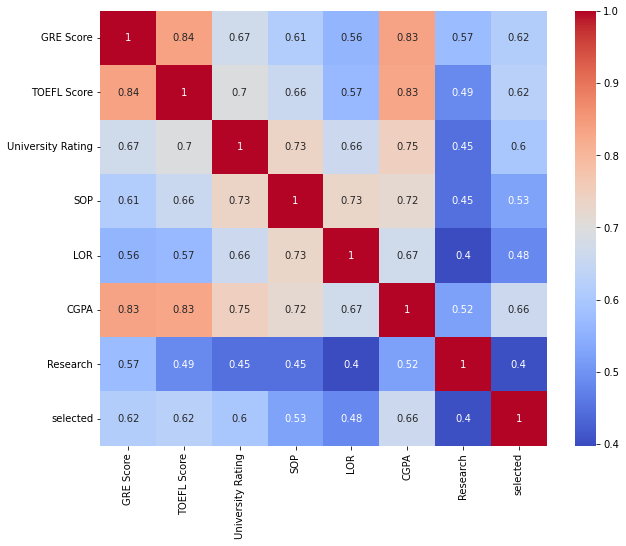

In [27]:
import seaborn as sns

cor = score.corr(numeric_only=True)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cor,
    annot=True,
    cmap="coolwarm",

)

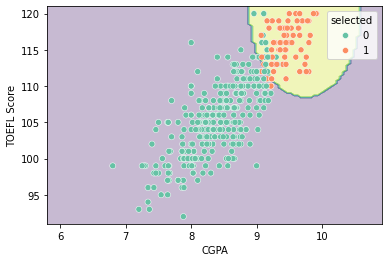

In [28]:
from sklearn.inspection import DecisionBoundaryDisplay

x_data = score[["CGPA", "TOEFL Score"]]
y_data = score["selected"]

naive1 = GaussianNB()
naive1.fit(x_data, y_data)

DecisionBoundaryDisplay.from_estimator(naive1, x_data, response_method="predict", alpha=0.3)

sns.scatterplot(data=score, x="CGPA", y="TOEFL Score",hue=y_data, palette="Set2")

plt.show()

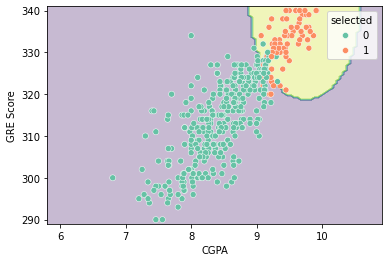

In [29]:
from sklearn.inspection import DecisionBoundaryDisplay

x_data = score[["CGPA", "GRE Score"]]
y_data = score["selected"]

naive2 = GaussianNB()
naive2.fit(x_data, y_data)

DecisionBoundaryDisplay.from_estimator(naive2, x_data, response_method="predict", alpha=0.3)

sns.scatterplot(data=score, x="CGPA", y="GRE Score",hue=y_data, palette="Set2")

plt.show()

In [31]:
gre = float(input("Enter GRE Score: "))
toefl = float(input("Enter TOEFL Score: "))
university_rating = int(input("Enter University Rating (1-5): "))
sop = float(input("Enter SOP strength (1-5): "))
lor = float(input("Enter LOR strength (1-5): "))
cgpa = float(input("Enter CGPA: "))
research = int(input("Research experience (0 or 1): "))

user_data = pd.DataFrame(
    [[gre, toefl, university_rating, sop, lor, cgpa, research]],
    columns=x.columns
)

tree_pred = tree2.predict(user_data)
naive_pred = naive.predict(user_data)



print("Decision Tree Prediction:", tree_pred)
print("Naive Bayes Prediction:", naive_pred)

if tree_pred[0] == 1:
    print("Decision Tree: Admitted")
else:
    print("Decision Tree: Not Admitted")


if naive_pred[0] == 1:
    print("Naive Bayes: Admitted")
else:
    print("Naive Bayes: Not Admitted")

Enter GRE Score: 325
Enter TOEFL Score: 104
Enter University Rating (1-5): 3
Enter SOP strength (1-5): 3
Enter LOR strength (1-5): 3.5
Enter CGPA: 9.11
Research experience (0 or 1): 1
Decision Tree Prediction: [0]
Naive Bayes Prediction: [0]
Decision Tree: Not Admitted
Naive Bayes: Not Admitted
